# Economics 5040: Dynamic Stochastic Modeling
## Problem Set 8 — Answer Key
### Income Risk, Precautionary Saving, and Self-Insurance

## Problem 1 — Two-Period Saving Under Income Risk

The household solves
$$
\max_{0\leq a_1<10}
\left\{\log(10-a_1)
+\frac{0.95}{2}\log(1.02a_1+2)
+\frac{0.95}{2}\log(1.02a_1+10)\right\}.
$$

For an interior optimum,
$$
\frac{1}{10-a_1}
=
0.95(1.02)\left[
\frac{1/2}{1.02a_1+2}
+\frac{1/2}{1.02a_1+10}
\right].
$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar

beta, R, y0 = 0.95, 1.02, 10.0
y1 = np.array([2.0, 10.0])
prob = np.array([0.5, 0.5])

def expected_utility(a1, y1=y1, prob=prob):
    c0 = y0 - a1
    c1 = R*a1 + y1
    if c0 <= 0 or np.any(c1 <= 0):
        return -np.inf
    return np.log(c0) + beta*np.sum(prob*np.log(c1))

risky = minimize_scalar(lambda a: -expected_utility(a),
                        bounds=(0, y0-1e-10), method="bounded")
a_risky = risky.x

y1_certain = np.array([6.0])
p_certain = np.array([1.0])

certain = minimize_scalar(
    lambda a: -expected_utility(a, y1_certain, p_certain),
    bounds=(0, y0-1e-10), method="bounded")
a_certain = certain.x

print("Risky-income saving:", a_risky)
print("Certain-income saving:", a_certain)
print("Risky c0:", y0-a_risky)
print("Risky c1 states:", R*a_risky+y1)

Risky-income saving: 2.7670077053355433
Certain-income saving: 1.8552036163487209
Risky c0: 7.232992294664457
Risky c1 states: [ 4.82234786 12.82234786]


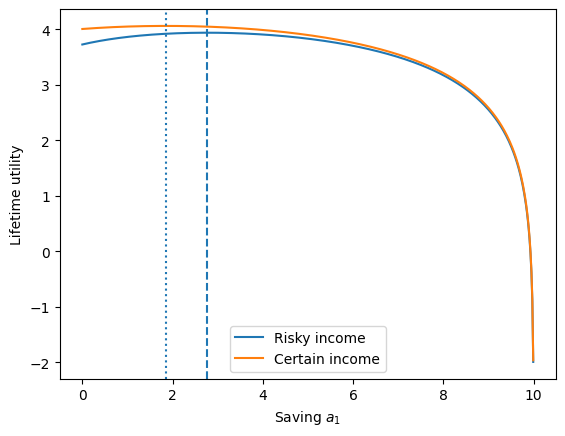

In [2]:
agrid = np.linspace(0, 9.99, 500)
Ur = np.array([expected_utility(a) for a in agrid])
Uc = np.array([expected_utility(a, y1_certain, p_certain) for a in agrid])

plt.plot(agrid, Ur, label="Risky income")
plt.plot(agrid, Uc, label="Certain income")
plt.axvline(a_risky, linestyle="--")
plt.axvline(a_certain, linestyle=":")
plt.xlabel("Saving $a_1$")
plt.ylabel("Lifetime utility")
plt.legend()
plt.show()

The risky economy generates more saving. With concave utility, marginal utility is especially high in the low-income state. An extra unit of assets therefore has a particularly valuable payoff when income is low. This is **precautionary saving**.

With actuarially fair complete insurance, the household could transfer resources directly across income states. The need to hold assets as a buffer against this idiosyncratic risk would be reduced.

## Problem 2 — Infinite-Horizon Income Fluctuation Problem

The state is \((a,z)\), the choice is \(a'\), and consumption is
$$
c=Ra+z-a'.
$$

The Bellman equation is
$$
V(a,z)=\max_{a'\geq0}
\left\{u(Ra+z-a')+
\beta\sum_{z'}P(z,z')V(a',z')\right\}.
$$

When the borrowing constraint is slack,
$$
u'(c_t)=\beta R E_t[u'(c_{t+1})].
$$
At the borrowing constraint the household would like, weakly, to move resources from the future toward the present, so the Euler condition becomes an inequality.

In [3]:
beta, R, rho = 0.96, 1.02, 2.0
z_grid = np.array([1.0, 2.0])
P = np.array([[0.90, 0.10],
              [0.20, 0.80]])
a_grid = np.linspace(0.0, 20.0, 201)

def u(c):
    c = np.asarray(c)
    ans = np.full(c.shape, -1e12, dtype=float)
    good = c > 0
    if rho == 1:
        ans[good] = np.log(c[good])
    else:
        ans[good] = (c[good]**(1-rho)-1)/(1-rho)
    return ans

def solve_ifp(z_grid, P, tol=1e-8, max_iter=2000):
    n_a, n_z = len(a_grid), len(z_grid)
    V = np.zeros((n_a, n_z))
    pol_idx = np.zeros((n_a, n_z), dtype=int)

    for it in range(max_iter):
        Vnew = np.empty_like(V)
        for iz, z in enumerate(z_grid):
            EV = V @ P[iz, :]
            for ia, a in enumerate(a_grid):
                c = R*a + z - a_grid
                values = u(c) + beta*EV
                j = np.argmax(values)
                Vnew[ia, iz] = values[j]
                pol_idx[ia, iz] = j

        err = np.max(np.abs(Vnew-V))
        V = Vnew
        if err < tol:
            print("Converged after", it+1, "iterations")
            break

    a_pol = a_grid[pol_idx]
    c_pol = R*a_grid[:, None] + z_grid[None, :] - a_pol
    return V, pol_idx, a_pol, c_pol

V, pol_idx, a_pol, c_pol = solve_ifp(z_grid, P)

Converged after 415 iterations


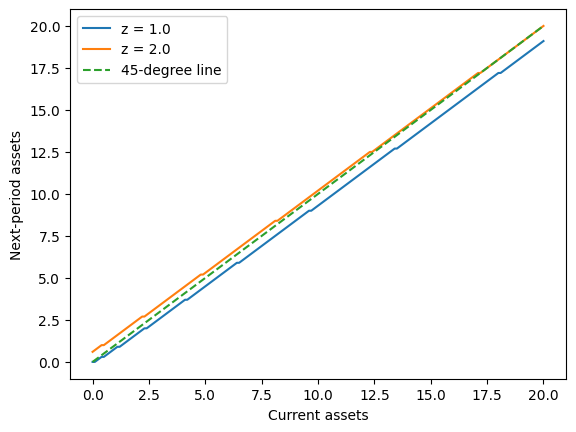

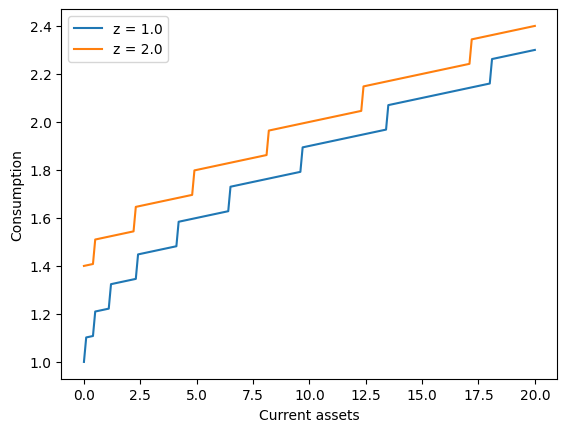

In [4]:
for iz, z in enumerate(z_grid):
    plt.plot(a_grid, a_pol[:, iz], label=f"z = {z}")
plt.plot(a_grid, a_grid, linestyle="--", label="45-degree line")
plt.xlabel("Current assets")
plt.ylabel("Next-period assets")
plt.legend()
plt.show()

for iz, z in enumerate(z_grid):
    plt.plot(a_grid, c_pol[:, iz], label=f"z = {z}")
plt.xlabel("Current assets")
plt.ylabel("Consumption")
plt.legend()
plt.show()

The household saves more when current income is high and can draw down its buffer when income is low. Near zero assets, the borrowing constraint limits the household's ability to smooth a bad income realization by borrowing against future income.

## Problem 3 — Self-Insurance in Simulation

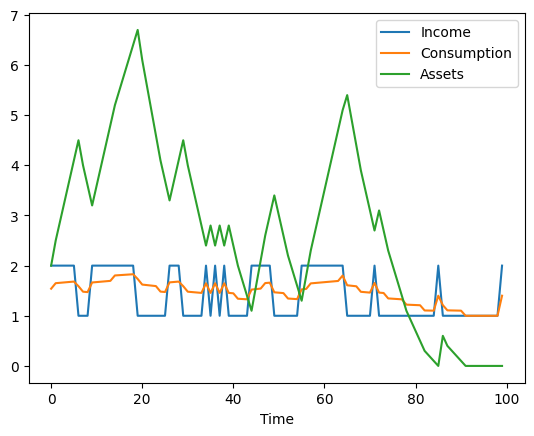

Income:      mean = 1.3175 sd = 0.46550375938331584
Consumption: mean = 1.3516750000000002 sd = 0.2426850518161348
Assets:      mean = 1.7525 sd = 1.673945563631028


In [5]:
def simulate(a_pol, z_grid, P, T=1000, a0=2.0, z0_index=1, seed=1234):
    rng = np.random.default_rng(seed)
    assets = np.empty(T+1)
    zind = np.empty(T, dtype=int)
    income = np.empty(T)
    cons = np.empty(T)

    assets[0] = a0
    iz = z0_index

    for t in range(T):
        zind[t] = iz
        income[t] = z_grid[iz]

        ia = np.argmin(np.abs(a_grid-assets[t]))
        ap = a_pol[ia, iz]
        cons[t] = R*assets[t] + income[t] - ap
        assets[t+1] = ap

        iz = rng.choice(len(z_grid), p=P[iz])

    return assets, income, cons, zind

assets, income, cons, zind = simulate(a_pol, z_grid, P)

t = np.arange(100)
plt.plot(t, income[:100], label="Income")
plt.plot(t, cons[:100], label="Consumption")
plt.plot(t, assets[:100], label="Assets")
plt.xlabel("Time")
plt.legend()
plt.show()

burn = 200
print("Income:      mean =", income[burn:].mean(),
      "sd =", income[burn:].std())
print("Consumption: mean =", cons[burn:].mean(),
      "sd =", cons[burn:].std())
print("Assets:      mean =", assets[burn:-1].mean(),
      "sd =", assets[burn:-1].std())

In [6]:
# No-saving benchmark: with a'=0 each period and no inherited assets,
# consumption simply equals current labor income.
cons_no_saving = income.copy()

print("SD consumption with saving:   ", cons[burn:].std())
print("SD consumption without saving:", cons_no_saving[burn:].std())

SD consumption with saving:    0.2426850518161348
SD consumption without saving: 0.46550375938331584


Consumption is smoother than income because assets absorb part of the income shock. In high-income periods the household builds the asset buffer; in low-income periods it can reduce saving or draw down assets.

This is **self-insurance**: in the absence of complete state-contingent insurance, the household uses a noncontingent asset to transfer resources across dates and partially protect consumption from idiosyncratic income shocks.

## Problem 4 — Precautionary Saving and the Amount of Risk

Because the transition matrix is unchanged, preserving the stationary mean is easy if we shrink both income states toward the original stationary mean.

In [7]:
# Stationary distribution
A = np.vstack((P.T - np.eye(2), np.ones(2)))
b = np.array([0.0, 0.0, 1.0])
pi = np.linalg.lstsq(A, b, rcond=None)[0]

zbar = pi @ z_grid
print("Stationary distribution:", pi)
print("Stationary mean income:", zbar)

# Shrink the income states halfway toward their mean.
z_less_risky = zbar + 0.5*(z_grid-zbar)

print("Benchmark income states:", z_grid)
print("Less risky income states:", z_less_risky)
print("New stationary mean:", pi @ z_less_risky)

V2, idx2, a_pol2, c_pol2 = solve_ifp(z_less_risky, P)

Stationary distribution: [0.66666667 0.33333333]
Stationary mean income: 1.3333333333333333
Benchmark income states: [1. 2.]
Less risky income states: [1.16666667 1.66666667]
New stationary mean: 1.3333333333333335
Converged after 417 iterations


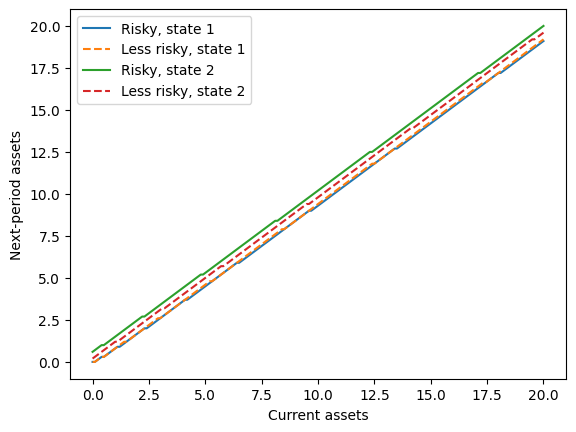

Mean assets, riskier income:    2.2216250000000004
Mean assets, less risky income: 0.565125


In [8]:
for iz in range(2):
    plt.plot(a_grid, a_pol[:, iz],
             label=f"Risky, state {iz+1}")
    plt.plot(a_grid, a_pol2[:, iz], linestyle="--",
             label=f"Less risky, state {iz+1}")

plt.xlabel("Current assets")
plt.ylabel("Next-period assets")
plt.legend()
plt.show()

assets_r, income_r, cons_r, _ = simulate(a_pol, z_grid, P, seed=2026)
assets_l, income_l, cons_l, _ = simulate(a_pol2, z_less_risky, P, seed=2026)

print("Mean assets, riskier income:   ", assets_r[200:-1].mean())
print("Mean assets, less risky income:", assets_l[200:-1].mean())

With greater uninsurable income risk, households generally desire a larger buffer of assets. This is the precautionary-saving motive.

The three concepts can now be separated:

- **Consumption smoothing** is the objective: households prefer to avoid large fluctuations in marginal utility and consumption.
- **Self-insurance** is a mechanism: households use asset accumulation and decumulation to transfer resources across dates when explicit insurance is unavailable.
- **Precautionary saving** is the additional desire to hold assets generated by uncertainty about future resources.

Thus precautionary saving helps build the buffer stock that makes self-insurance possible, and self-insurance helps the household smooth consumption.

## What surprised me?

Answers will differ. A strong response should identify a specific numerical or theoretical result and explain why it was initially unexpected.